# NumPy
## 데이터 분석 입문자를 위한 배열 연산 교안

---

### 왜 NumPy부터인가

pandas, scikit-learn, Matplotlib, PyTorch — 데이터 분석에 쓰는 거의 모든 라이브러리가 **속으로는 NumPy 배열**을 다룹니다.

```
    pandas      scikit-learn      matplotlib      PyTorch
       |              |                |              |
       +--------------+----------------+--------------+
                             |
                      ┌──────▼──────┐
                      │   NumPy     │   ← ndarray
                      └─────────────┘
```

그래서 NumPy를 알면 오류 메시지가 읽히고, 남의 코드가 이해되고, 느린 코드를 빠르게 고칠 수 있습니다.


### 학습 방법

- 셀을 **직접 실행**하고, 값을 바꿔가며 결과를 확인하세요.
- 배열이 나오면 **`.shape` 을 먼저 찍어 보는 습관**을 들이세요. NumPy 오류의 90%는 shape 문제입니다.

---

# Part 0. NumPy란?

## 0.1 한 줄 요약

> **같은 타입의 숫자를 한 덩어리로 모아 놓고, 통째로 계산하는 라이브러리.**

핵심 자료형은 **`ndarray`** (N-dimensional array, 다차원 배열) 하나뿐입니다.

## 0.2 파이썬 리스트와 무엇이 다른가

| | 파이썬 `list` | NumPy `ndarray` |
|---|---|---|
| 담는 것 | 아무 타입이나 섞어서 | **한 가지 타입만** |
| 메모리 | 값들이 흩어져 있음 (포인터 배열) | **연속된 한 덩어리** |
| 연산 | 반복문 필요 | **통째로 한 번에** |
| `a + b` | 이어붙이기 | **원소별 덧셈** |
| 속도 | 느림 | **10~100배 빠름** |
| 차원 | 중첩 리스트로 흉내 | **진짜 다차원** |

## 0.3 왜 빠른가

세 가지 이유가 있습니다.

1. **연속 메모리** — 값들이 한 줄로 붙어 있어 CPU가 캐시에 한꺼번에 올립니다.
2. **타입 고정** — 매번 타입을 확인할 필요가 없습니다.
3. **C로 구현된 반복문** — 파이썬 인터프리터를 거치지 않습니다.

```
[파이썬 리스트]  각 원소가 별도 객체 → 포인터를 따라 흩어진 메모리를 방문
   ┌───┐   ┌───┐   ┌───┐
   │ * │──▶│ 1 │   │ 2 │ ...        느림
   └───┘   └───┘   └───┘

[NumPy 배열]  값이 한 덩어리로 나란히
   ┌───┬───┬───┬───┬───┐
   │ 1 │ 2 │ 3 │ 4 │ 5 │           빠름
   └───┴───┴───┴───┴───┘
```

In [1]:
import numpy as np
import time

print('NumPy', np.__version__)

# 보기 좋게 출력하는 설정 (선택)
np.set_printoptions(precision=3, suppress=True, linewidth=100)

NumPy 2.0.2


In [3]:
# 리스트와 배열의 결정적 차이
py_list = [1, 2, 3, 4]
np_arr = np.array([1, 2, 3, 4])

# 리스트끼리 + 연산을 하면 리스트를 이어붙임.
print('리스트 + 리스트 :', py_list + py_list)     # 이어붙이기
# Numpy는 배열끼리 +연산을 하면 같은 위치의 원소끼리 더함.
print('배열   + 배열   :', np_arr + np_arr)       # 원소별 덧셈
print()
print('리스트 * 2 :', py_list * 2)                # 반복
print('배열   * 2 :', np_arr * 2)                 # 각 원소에 2배
print()
# py_list+10을 실행하면 Typerror가 발생
try: #시도를 하였는데, error가 발생하니깐 Typerror로 빠짐.
    py_list + 10
# Typerrror가 발생하면 오류 내용을 e에 저장.
except TypeError as e:
    print('리스트 + 10 → TypeError:', e)
print('배열   + 10 :', np_arr + 10)

# 리스트를 자료로 묶어서 관리하는 초점, Numpy 배열은 원소별 수치 계산이 초점

리스트 + 리스트 : [1, 2, 3, 4, 1, 2, 3, 4]
배열   + 배열   : [2 4 6 8]

리스트 * 2 : [1, 2, 3, 4, 1, 2, 3, 4]
배열   * 2 : [2 4 6 8]

리스트 + 10 → TypeError: can only concatenate list (not "int") to list
배열   + 10 : [11 12 13 14]


In [4]:
# 속도 비교 — 100만 개 원소 제곱하기
import sys

n = 1_000_000
lst = list(range(n))
arr = np.arange(n)

t0 = time.perf_counter() #코드가 실행되는 데 걸린 시간을 정밀하게 측정할 때 사용하는 함수
res_list = [x * x for x in lst]
t1 = time.perf_counter()
res_arr = arr * arr
t2 = time.perf_counter()

print(f'파이썬 리스트 : {t1-t0:.4f}초')
print(f'NumPy 배열    : {t2-t1:.4f}초')
print(f'배율          : {(t1-t0)/(t2-t1):.0f}배 빠름')

print('\n메모리 사용량')
print(f'  리스트 : {sys.getsizeof(lst)/1e6:.1f} MB (+ 각 정수 객체 별도)')
print(f'  배열   : {arr.nbytes/1e6:.1f} MB')

파이썬 리스트 : 0.0655초
NumPy 배열    : 0.0059초
배율          : 11배 빠름

메모리 사용량
  리스트 : 8.0 MB (+ 각 정수 객체 별도)
  배열   : 8.0 MB


---

# Part 1. 배열 만들기

## 1.1 리스트에서 만들기 — `np.array()`

In [5]:
a1 = np.array([1, 2, 3, 4, 5])                        # 1차원
a2 = np.array([[1, 2, 3], [4, 5, 6]])                 # 2차원
a3 = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])   # 3차원

for name, a in [('1차원', a1), ('2차원', a2), ('3차원', a3)]:
    print(f'{name}  shape={a.shape}  ndim={a.ndim}  dtype={a.dtype}')
    print(a)
    print()

1차원  shape=(5,)  ndim=1  dtype=int64
[1 2 3 4 5]

2차원  shape=(2, 3)  ndim=2  dtype=int64
[[1 2 3]
 [4 5 6]]

3차원  shape=(2, 2, 2)  ndim=3  dtype=int64
[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]



```
[1차원]  shape=(5,)        [5]
   ┌───┬───┬───┬───┬───┐
   │ 1 │ 2 │ 3 │ 4 │ 5 │
   └───┴───┴───┴───┴───┘

[2차원]  shape=(2, 3)      [행, 열]
   ┌───┬───┬───┐
   │ 1 │ 2 │ 3 │   ← axis=0 방향 (행)
   ├───┼───┼───┤
   │ 4 │ 5 │ 6 │
   └───┴───┴───┘
     ↑ axis=1 방향 (열)

[3차원]  shape=(2, 2, 2)   [면, 행, 열]
```

> **`shape` 은 항상 바깥쪽 차원부터** 적힙니다. `(2, 3)` 이면 '2개의 행, 각 행에 3개' 라는 뜻입니다.

## 1.2 값을 채워서 만들기

| 함수 | 결과 |
|---|---|
| `np.zeros(shape)` | 0으로 채움 |
| `np.ones(shape)` | 1로 채움 |
| `np.full(shape, v)` | v로 채움 |
| `np.empty(shape)` | **초기화 안 함** (쓰레기값, 가장 빠름) |
| `np.eye(n)` | 단위행렬 |
| `np.zeros_like(a)` | a와 같은 shape·dtype의 0 배열 |

In [6]:
print('zeros(3,4)\n', np.zeros((3, 4)))
print('\nones(2,3)\n', np.ones((2, 3), dtype=int))
print('\nfull(2,3, 7)\n', np.full((2, 3), 7))
print('\neye(3)\n', np.eye(3))

base = np.array([[1, 2, 3], [4, 5, 6]])
print('\nzeros_like(base)\n', np.zeros_like(base))
print('\nones_like(base)\n', np.ones_like(base))

zeros(3,4)
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

ones(2,3)
 [[1 1 1]
 [1 1 1]]

full(2,3, 7)
 [[7 7 7]
 [7 7 7]]

eye(3)
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

zeros_like(base)
 [[0 0 0]
 [0 0 0]]

ones_like(base)
 [[1 1 1]
 [1 1 1]]


## 1.3 수열 만들기

| 함수 | 뜻 | 끝값 포함? |
|---|---|---|
| `np.arange(start, stop, step)` | 간격을 지정 | **미포함** |
| `np.linspace(start, stop, num)` | 개수를 지정 | **포함** (기본) |
| `np.logspace(a, b, num)` | 로그 간격 | 포함 |

> **헷갈리는 지점:** `arange` 는 `range` 처럼 끝값을 뺍니다. `linspace` 는 끝값을 넣습니다.
> 소수 간격이 필요하면 `arange(0, 1, 0.1)` 보다 **`linspace` 를 쓰세요.** 부동소수점 오차로 원소 개수가 달라질 수 있습니다.

In [7]:
print('arange(10)        :', np.arange(10))
print('arange(2, 10, 2)  :', np.arange(2, 10, 2))
print('arange(0, 1, 0.2) :', np.arange(0, 1, 0.2))
print()
print('linspace(0, 1, 5) :', np.linspace(0, 1, 5))
print('linspace(0, 1, 5, endpoint=False) :', np.linspace(0, 1, 5, endpoint=False))
print()
print('logspace(0, 3, 4) :', np.logspace(0, 3, 4))     # 10^0 ~ 10^3

print('\n부동소수점 함정')
print('  arange(0, 0.3, 0.1) 길이 :', len(np.arange(0, 0.3, 0.1)))
print('  값 :', np.arange(0, 0.3, 0.1))

arange(10)        : [0 1 2 3 4 5 6 7 8 9]
arange(2, 10, 2)  : [2 4 6 8]
arange(0, 1, 0.2) : [0.  0.2 0.4 0.6 0.8]

linspace(0, 1, 5) : [0.   0.25 0.5  0.75 1.  ]
linspace(0, 1, 5, endpoint=False) : [0.  0.2 0.4 0.6 0.8]

logspace(0, 3, 4) : [   1.   10.  100. 1000.]

부동소수점 함정
  arange(0, 0.3, 0.1) 길이 : 3
  값 : [0.  0.1 0.2]


## 1.4 난수 — 새 API를 쓰세요

NumPy 1.17부터 **`np.random.default_rng()`** 방식이 권장됩니다. 예전 `np.random.rand()` 방식은 전역 상태를 쓰기 때문에 재현이 어렵습니다.

| 구버전 (비권장) | 신버전 (권장) |
|---|---|
| `np.random.seed(42)` | `rng = np.random.default_rng(42)` |
| `np.random.rand(3)` | `rng.random(3)` |
| `np.random.randn(3)` | `rng.standard_normal(3)` |
| `np.random.randint(0, 10, 5)` | `rng.integers(0, 10, 5)` |
| `np.random.choice(...)` | `rng.choice(...)` |
| `np.random.shuffle(a)` | `rng.shuffle(a)` |

In [8]:
rng = np.random.default_rng(42)      # seed 를 주면 항상 같은 결과

print('균등분포 [0,1)       :', rng.random(5))
print('정규분포 (0, 1)      :', rng.standard_normal(5))
print('정규분포 (평균50,σ10):', rng.normal(50, 10, 5))
print('정수 [0, 10)         :', rng.integers(0, 10, 8))
print('선택 (복원)          :', rng.choice(['A', 'B', 'C'], 8))
print('선택 (확률 지정)     :', rng.choice(['A', 'B'], 8, p=[0.8, 0.2]))

deck = np.arange(10)
print('\n섞기 전 :', deck)
rng.shuffle(deck)                     # 원본을 직접 섞음
print('섞은 후 :', deck)
print('순열 (원본 유지) :', rng.permutation(np.arange(10)))

균등분포 [0,1)       : [0.774 0.439 0.859 0.697 0.094]
정규분포 (0, 1)      : [-1.302  0.128 -0.316 -0.017 -0.853]
정규분포 (평균50,σ10): [58.794 57.778 50.66  61.272 54.675]
정수 [0, 10)         : [4 2 0 5 8 0 8 8]
선택 (복원)          : ['A' 'B' 'A' 'C' 'C' 'B' 'A' 'C']
선택 (확률 지정)     : ['B' 'A' 'A' 'A' 'A' 'A' 'A' 'A']

섞기 전 : [0 1 2 3 4 5 6 7 8 9]
섞은 후 : [5 4 9 6 0 7 8 1 2 3]
순열 (원본 유지) : [4 3 0 6 8 2 7 1 5 9]


In [9]:
# 재현성 확인 — 같은 seed 는 항상 같은 값
print(np.random.default_rng(0).integers(0, 100, 5))
print(np.random.default_rng(0).integers(0, 100, 5))
print(np.random.default_rng(1).integers(0, 100, 5))    # seed 가 다르면 다름

[85 63 51 26 30]
[85 63 51 26 30]
[47 51 75 95  3]


---

# Part 2. 배열의 속성과 dtype

## 2.1 속성 6종

| 속성 | 뜻 |
|---|---|
| `.shape` | 각 차원의 크기 (튜플) |
| `.ndim` | 차원 수 (= `len(shape)`) |
| `.size` | 전체 원소 개수 (shape의 곱) |
| `.dtype` | 원소의 자료형 |
| `.itemsize` | 원소 하나의 바이트 크기 |
| `.nbytes` | 전체 바이트 크기 (`size × itemsize`) |

In [10]:
a = np.arange(24).reshape(2, 3, 4)

print(a)
print()
for attr in ['shape', 'ndim', 'size', 'dtype', 'itemsize', 'nbytes']:
    print(f'  {attr:10s} = {getattr(a, attr)}')

[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

  shape      = (2, 3, 4)
  ndim       = 3
  size       = 24
  dtype      = int64
  itemsize   = 8
  nbytes     = 192


## 2.2 dtype — 자료형

| 종류 | 예 | 설명 |
|---|---|---|
| 정수 | `int8`, `int16`, `int32`, `int64` | 뒤 숫자는 비트 수 |
| 부호 없는 정수 | `uint8` (0~255) | 이미지에 많이 씀 |
| 실수 | `float16`, `float32`, `float64` | 기본은 `float64` |
| 복소수 | `complex64`, `complex128` | |
| 불리언 | `bool_` | True / False |
| 문자열 | `<U5` | 유니코드 최대 5글자 |
| 아무거나 | `object` | **느림. 되도록 피하세요** |

> **왜 신경 써야 하나**
> - `int8` 은 −128~127 밖에 못 담습니다. 넘으면 **조용히 값이 망가집니다.**
> - `float32` 는 `float64` 의 절반 메모리를 씁니다. 대용량에서 중요합니다.

In [11]:
print('정수 리스트   →', np.array([1, 2, 3]).dtype)
print('실수 섞임     →', np.array([1, 2, 3.0]).dtype)          # 하나만 실수여도 전부 실수
print('문자 섞임     →', np.array([1, 2, 'three']).dtype)      # 전부 문자열이 됨
print('불리언        →', np.array([True, False]).dtype)

print('\n지정 :', np.array([1, 2, 3], dtype=np.float32).dtype)
print('변환 :', np.array([1.7, 2.9, -3.1]).astype(int))         # 0 방향으로 버림

정수 리스트   → int64
실수 섞임     → float64
문자 섞임     → <U21
불리언        → bool

지정 : float32
변환 : [ 1  2 -3]


In [12]:
# 오버플로 — 조용히 값이 망가지는 사고
small = np.array([120, 125], dtype=np.int8)      # 범위 -128 ~ 127
print('원본       :', small)
print('+10 하면?  :', small + np.int8(10))       # 127을 넘어 음수로 돌아감

print('\n각 타입의 범위')
for t in [np.int8, np.int16, np.int32]:
    info = np.iinfo(t)
    print(f'  {t.__name__:8s} {info.min:>12,} ~ {info.max:>12,}')
print(f'  float32  최대 {np.finfo(np.float32).max:.3e}')
print(f'  float64  최대 {np.finfo(np.float64).max:.3e}')

원본       : [120 125]
+10 하면?  : [-126 -121]

각 타입의 범위
  int8             -128 ~          127
  int16         -32,768 ~       32,767
  int32    -2,147,483,648 ~ 2,147,483,647
  float32  최대 3.403e+38
  float64  최대 1.798e+308


In [13]:
# 메모리 절약 — 값 범위를 알면 작은 타입을 쓰세요
for name, t in [('float64', np.float64), ('float32', np.float32), ('uint8', np.uint8)]:
    x = np.ones(1_000_000, dtype=t)
    print(f'  {name:8s} {x.nbytes/1e6:6.1f} MB')

  float64     8.0 MB
  float32     4.0 MB
  uint8       1.0 MB


---

# Part 3. 인덱싱과 슬라이싱

## 3.1 기본 인덱싱

In [14]:
a = np.arange(10)
print('a          :', a)
print('a[0]       :', a[0])
print('a[-1]      :', a[-1])
print('a[2:5]     :', a[2:5])
print('a[:3]      :', a[:3])
print('a[::2]     :', a[::2])       # 2칸씩
print('a[::-1]    :', a[::-1])      # 뒤집기

a          : [0 1 2 3 4 5 6 7 8 9]
a[0]       : 0
a[-1]      : 9
a[2:5]     : [2 3 4]
a[:3]      : [0 1 2]
a[::2]     : [0 2 4 6 8]
a[::-1]    : [9 8 7 6 5 4 3 2 1 0]


In [15]:
m = np.arange(1, 13).reshape(3, 4)
print(m)
print()
print('m[1, 2]     =', m[1, 2])        # 1행 2열 — 콤마로 씁니다
print('m[1][2]     =', m[1][2])        # 같은 결과지만 느림 (중간 배열 생성)
print()
print('m[0]        =', m[0])           # 0행 전체
print('m[:, 1]     =', m[:, 1])        # 1열 전체
print('m[1:, 2:]   =\n', m[1:, 2:])    # 부분 행렬
print('m[:, ::-1]  =\n', m[:, ::-1])   # 열 순서 뒤집기

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

m[1, 2]     = 7
m[1][2]     = 7

m[0]        = [1 2 3 4]
m[:, 1]     = [ 2  6 10]
m[1:, 2:]   =
 [[ 7  8]
 [11 12]]
m[:, ::-1]  =
 [[ 4  3  2  1]
 [ 8  7  6  5]
 [12 11 10  9]]


> **`m[1, 2]` 로 쓰세요.** `m[1][2]` 는 중간 배열을 한 번 더 만들어 느리고, 슬라이스가 섞이면 결과가 달라집니다.

## 3.2 슬라이스는 복사본이 아니다 — **view**

**이 교안에서 가장 중요한 개념입니다.**

파이썬 리스트의 슬라이스는 **복사본**입니다. NumPy 배열의 슬라이스는 **원본을 들여다보는 창(view)** 입니다. 그래서 슬라이스를 고치면 **원본이 바뀝니다.**

In [16]:
# 리스트: 슬라이스가 복사본
lst = [0, 1, 2, 3, 4]
part = lst[1:4]
part[0] = 999
print('리스트 원본 :', lst)          # 안 바뀜

# 배열: 슬라이스가 view
arr = np.array([0, 1, 2, 3, 4])
view = arr[1:4]
view[0] = 999
print('배열 원본   :', arr)          # 바뀜!

print()
print('view 인가?         :', view.base is not None)
print('메모리를 공유하나? :', np.shares_memory(arr, view))

리스트 원본 : [0, 1, 2, 3, 4]
배열 원본   : [  0 999   2   3   4]

view 인가?         : True
메모리를 공유하나? : True


In [ ]:
# 원본을 지키려면 .copy()
arr = np.array([0, 1, 2, 3, 4])
safe = arr[1:4].copy()
safe[0] = 999

print('원본  :', arr)                 # 안 바뀜
print('사본  :', safe)
print('공유? :', np.shares_memory(arr, safe))

원본  : [0 1 2 3 4]
사본  : [999   2   3]
공유? : False


### view가 되는 것 / copy가 되는 것

| 연산 | 결과 |
|---|---|
| 슬라이싱 `a[1:5]`, `a[:, 0]` | **view** |
| `reshape`, `ravel`, `.T`, `transpose` | **view** (가능할 때) |
| fancy indexing `a[[0, 2, 4]]` | **copy** |
| boolean masking `a[a > 3]` | **copy** |
| `flatten()` | **copy** (항상) |
| `astype()`, 산술 연산 | **copy** |

> **판별법:** `x.base is not None` 이거나 `np.shares_memory(a, x)` 가 True면 view입니다.
> **원칙:** 원본을 건드리면 안 되는 상황에서는 **의심되면 `.copy()`** 를 붙이세요.

In [ ]:
a = np.arange(12).reshape(3, 4)

tests = [
    ('슬라이싱   a[0:2]',      a[0:2]),
    ('열 선택    a[:, 1]',     a[:, 1]),
    ('reshape',                a.reshape(4, 3)),
    ('전치       a.T',         a.T),
    ('ravel',                  a.ravel()),
    ('flatten',                a.flatten()),
    ('fancy      a[[0, 2]]',   a[[0, 2]]),
    ('boolean    a[a > 5]',    a[a > 5]),
    ('astype',                 a.astype(float)),
]
for name, x in tests:
    kind = 'view' if np.shares_memory(a, x) else 'copy'
    print(f'  {name:22s} → {kind}')

  슬라이싱   a[0:2]          → view
  열 선택    a[:, 1]        → view
  reshape                → view
  전치       a.T           → view
  ravel                  → view
  flatten                → copy
  fancy      a[[0, 2]]   → copy
  boolean    a[a > 5]    → copy
  astype                 → copy


## 3.3 팬시 인덱싱 — 원하는 위치만 골라내기

인덱스 **배열**을 넘겨 순서와 중복까지 자유롭게 고릅니다.

In [ ]:
a = np.array([10, 20, 30, 40, 50])

print('a[[0, 2, 4]]       :', a[[0, 2, 4]])
print('a[[4, 4, 0]]       :', a[[4, 4, 0]])      # 중복·순서 자유

m = np.arange(1, 13).reshape(3, 4)
print('\nm\n', m)
print('\nm[[0, 2]]   (0행과 2행)\n', m[[0, 2]])
print('\nm[[0, 1, 2], [0, 2, 3]]   짝지어 (0,0),(1,2),(2,3)\n',
      m[[0, 1, 2], [0, 2, 3]])
print('\nm[np.ix_([0,2],[1,3])]    0·2행 x 1·3열 격자\n',
      m[np.ix_([0, 2], [1, 3])])

a[[0, 2, 4]]       : [10 30 50]
a[[4, 4, 0]]       : [50 50 10]

m
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

m[[0, 2]]   (0행과 2행)
 [[ 1  2  3  4]
 [ 9 10 11 12]]

m[[0, 1, 2], [0, 2, 3]]   짝지어 (0,0),(1,2),(2,3)
 [ 1  7 12]

m[np.ix_([0,2],[1,3])]    0·2행 x 1·3열 격자
 [[ 2  4]
 [10 12]]


> **주의:** `m[[0,1,2], [0,2,3]]` 은 '0·1·2행과 0·2·3열의 격자'가 **아닙니다.** 인덱스를 **짝지어** (0,0), (1,2), (2,3) 을 뽑습니다.
> 격자를 원하면 `np.ix_()` 를 쓰세요.

## 3.4 불리언 마스킹 — 조건으로 골라내기

**실무에서 가장 많이 쓰는 인덱싱입니다.**

In [ ]:
scores = np.array([88, 45, 92, 67, 78, 95, 33, 71])

mask = scores >= 70
print('점수      :', scores)
print('mask      :', mask)                 # True/False 배열
print('70점 이상 :', scores[mask])
print('한 줄로   :', scores[scores >= 70])

print('\n개수 세기 :', (scores >= 70).sum())     # True=1 이므로 합 = 개수
print('비율      :', (scores >= 70).mean())     # 평균 = 비율

점수      : [88 45 92 67 78 95 33 71]
mask      : [ True False  True False  True  True False  True]
70점 이상 : [88 92 78 95 71]
한 줄로   : [88 92 78 95 71]

개수 세기 : 5
비율      : 0.625


### 조건을 여러 개 붙일 때 — `&`, `|`, `~` 와 괄호

> **`and`, `or`, `not` 은 쓸 수 없습니다.** 반드시 `&`, `|`, `~` 를 쓰고 **각 조건을 괄호로 감싸세요.** 우선순위 때문에 괄호를 빼면 오류가 납니다.

In [ ]:
print('70 이상 90 미만      :', scores[(scores >= 70) & (scores < 90)])
print('50 미만 또는 90 이상 :', scores[(scores < 50) | (scores >= 90)])
print('70 미만 (~ 사용)     :', scores[~(scores >= 70)])

try:
    scores[scores >= 70 and scores < 90]
except ValueError as e:
    print('\nand 사용 → ValueError:', str(e)[:70], '...')

try:
    scores[scores >= 70 & scores < 90]        # 괄호 없음
except Exception as e:
    print('괄호 누락 →', type(e).__name__)

70 이상 90 미만      : [88 78 71]
50 미만 또는 90 이상 : [45 92 95 33]
70 미만 (~ 사용)     : [45 67 33]

and 사용 → ValueError: The truth value of an array with more than one element is ambiguous. U ...
괄호 누락 → ValueError


In [ ]:
# 마스크로 값 바꾸기 — 매우 자주 씁니다
x = np.array([3, -1, 4, -5, 9, -2, 6])

y = x.copy()
y[y < 0] = 0                       # 음수를 전부 0으로
print('음수를 0으로 :', y)

# np.where — 조건에 따라 다른 값 (삼항 연산자의 배열 버전)
print('where        :', np.where(x < 0, 0, x))
print('부호 표시    :', np.where(x < 0, '음수', '양수'))

# 조건을 만족하는 위치(인덱스) 찾기
print('\n음수의 위치  :', np.where(x < 0)[0])
print('첫 음수 위치 :', np.argmax(x < 0))    # 첫 True의 인덱스

음수를 0으로 : [3 0 4 0 9 0 6]
where        : [3 0 4 0 9 0 6]
부호 표시    : ['양수' '음수' '양수' '음수' '양수' '음수' '양수']

음수의 위치  : [1 3 5]
첫 음수 위치 : 1


---

# Part 4. 모양 바꾸기 · 합치기 · 나누기

## 4.1 `reshape`

원소 개수가 맞아야 합니다. **`-1` 은 '알아서 계산해라'** 는 뜻입니다.

In [ ]:
a = np.arange(12)
print('원본       :', a)
print('reshape(3,4)\n', a.reshape(3, 4))
print('reshape(2,6)\n', a.reshape(2, 6))
print('reshape(3,-1)  → -1 자리를 4로 자동 계산\n', a.reshape(3, -1))
print('reshape(-1,2)\n', a.reshape(-1, 2))
print('reshape(2,2,3) shape :', a.reshape(2, 2, 3).shape)

try:
    a.reshape(5, 3)          # 12 != 15
except ValueError as e:
    print('\n개수 안 맞으면 → ValueError:', e)

원본       : [ 0  1  2  3  4  5  6  7  8  9 10 11]
reshape(3,4)
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
reshape(2,6)
 [[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]
reshape(3,-1)  → -1 자리를 4로 자동 계산
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
reshape(-1,2)
 [[ 0  1]
 [ 2  3]
 [ 4  5]
 [ 6  7]
 [ 8  9]
 [10 11]]
reshape(2,2,3) shape : (2, 2, 3)

개수 안 맞으면 → ValueError: cannot reshape array of size 12 into shape (5,3)


## 4.2 평탄화 — `ravel` vs `flatten`

| | 반환 | 속도 |
|---|---|---|
| `ravel()` | **view** (가능하면) | 빠름 |
| `flatten()` | **항상 copy** | 느림 |

> 값을 읽기만 할 거면 `ravel()`, 원본을 지켜야 하면 `flatten()`.

In [ ]:
m = np.arange(6).reshape(2, 3)

r = m.ravel()
f = m.flatten()
r[0] = 999

print('ravel 수정 후 원본 :\n', m)          # 바뀜
print('flatten 결과       :', f)             # 안 바뀜
print('ravel 이 view?   :', np.shares_memory(m, r))
print('flatten 이 view? :', np.shares_memory(m, f))

ravel 수정 후 원본 :
 [[999   1   2]
 [  3   4   5]]
flatten 결과       : [0 1 2 3 4 5]
ravel 이 view?   : True
flatten 이 view? : False


## 4.3 전치와 축 바꾸기

In [ ]:
m = np.arange(6).reshape(2, 3)
print('원본 shape', m.shape, '\n', m)
print('\n전치 m.T shape', m.T.shape, '\n', m.T)

t = np.arange(24).reshape(2, 3, 4)
print('\n3차원 transpose')
print('  원본             :', t.shape)
print('  t.T              :', t.T.shape)                    # 축을 뒤집음
print('  transpose(1,0,2) :', t.transpose(1, 0, 2).shape)   # 원하는 순서로
print('  swapaxes(0,2)    :', t.swapaxes(0, 2).shape)
print('  moveaxis(0,-1)   :', np.moveaxis(t, 0, -1).shape)

원본 shape (2, 3) 
 [[0 1 2]
 [3 4 5]]

전치 m.T shape (3, 2) 
 [[0 3]
 [1 4]
 [2 5]]

3차원 transpose
  원본             : (2, 3, 4)
  t.T              : (4, 3, 2)
  transpose(1,0,2) : (3, 2, 4)
  swapaxes(0,2)    : (4, 3, 2)
  moveaxis(0,-1)   : (3, 4, 2)


## 4.4 차원 늘리기 · 줄이기

브로드캐스팅(Part 5)을 쓰려면 **차원을 하나 끼워 넣어야 할 때**가 많습니다.

In [ ]:
v = np.array([1, 2, 3])
print('원본            :', v.shape)
print('v[np.newaxis, :]:', v[np.newaxis, :].shape)   # (1, 3) 행벡터
print('v[:, np.newaxis]:', v[:, np.newaxis].shape)   # (3, 1) 열벡터
print('v[None, :]      :', v[None, :].shape)         # newaxis == None
print('expand_dims(0)  :', np.expand_dims(v, 0).shape)
print('reshape(-1, 1)  :', v.reshape(-1, 1).shape)   # 같은 결과

print('\n열벡터\n', v[:, np.newaxis])

z = np.zeros((1, 3, 1))
print('\nsqueeze 전 :', z.shape)
print('squeeze 후 :', z.squeeze().shape)              # 크기 1인 축 제거

원본            : (3,)
v[np.newaxis, :]: (1, 3)
v[:, np.newaxis]: (3, 1)
v[None, :]      : (1, 3)
expand_dims(0)  : (1, 3)
reshape(-1, 1)  : (3, 1)

열벡터
 [[1]
 [2]
 [3]]

squeeze 전 : (1, 3, 1)
squeeze 후 : (3,)


## 4.5 합치기

| 함수 | 하는 일 |
|---|---|
| `np.concatenate([a, b], axis=)` | **기존 축**을 따라 이어붙임 |
| `np.vstack` / `np.hstack` | 세로 / 가로로 붙임 |
| `np.stack([a, b], axis=)` | **새 축**을 만들어 쌓음 (차원이 늘어남) |
| `np.column_stack` | 1차원 배열들을 열로 세워 붙임 |

> **`concatenate` 와 `stack` 의 차이가 핵심입니다.**
> `concatenate` 는 차원이 그대로, `stack` 은 차원이 하나 늘어납니다.

In [ ]:
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7, 8]])

print('concatenate axis=0 (세로)  shape', np.concatenate([a, b], axis=0).shape)
print(np.concatenate([a, b], axis=0))
print('\nconcatenate axis=1 (가로)  shape', np.concatenate([a, b], axis=1).shape)
print(np.concatenate([a, b], axis=1))
print('\nstack axis=0  shape', np.stack([a, b], axis=0).shape, '  ← 차원이 늘어남')
print(np.stack([a, b], axis=0))

concatenate axis=0 (세로)  shape (4, 2)
[[1 2]
 [3 4]
 [5 6]
 [7 8]]

concatenate axis=1 (가로)  shape (2, 4)
[[1 2 5 6]
 [3 4 7 8]]

stack axis=0  shape (2, 2, 2)   ← 차원이 늘어남
[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]


In [ ]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])

print('vstack       shape', np.vstack([x, y]).shape, '\n', np.vstack([x, y]))
print('\nhstack       shape', np.hstack([x, y]).shape, '\n', np.hstack([x, y]))
print('\ncolumn_stack shape', np.column_stack([x, y]).shape, '\n', np.column_stack([x, y]))

vstack       shape (2, 3) 
 [[1 2 3]
 [4 5 6]]

hstack       shape (6,) 
 [1 2 3 4 5 6]

column_stack shape (3, 2) 
 [[1 4]
 [2 5]
 [3 6]]


## 4.6 나누기

In [ ]:
a = np.arange(12).reshape(3, 4)
print(a)

print('\nvsplit 3등분 :')
for p in np.vsplit(a, 3):
    print(' ', p.tolist())

print('\nhsplit 2등분 :')
for p in np.hsplit(a, 2):
    print(' ', p.tolist())

print('\n위치 지정 split (1행, 2행에서 자르기):')
for p in np.split(a, [1, 2], axis=0):
    print(' ', p.tolist())

print('\n균등 분할이 안 될 때는 array_split :')
for p in np.array_split(np.arange(7), 3):
    print(' ', p)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

vsplit 3등분 :
  [[0, 1, 2, 3]]
  [[4, 5, 6, 7]]
  [[8, 9, 10, 11]]

hsplit 2등분 :
  [[0, 1], [4, 5], [8, 9]]
  [[2, 3], [6, 7], [10, 11]]

위치 지정 split (1행, 2행에서 자르기):
  [[0, 1, 2, 3]]
  [[4, 5, 6, 7]]
  [[8, 9, 10, 11]]

균등 분할이 안 될 때는 array_split :
  [0 1 2]
  [3 4]
  [5 6]


---

# Part 5. 연산과 브로드캐스팅

## 5.1 벡터화 — 반복문을 지우는 것

NumPy 연산은 **원소별(element-wise)** 로 동작합니다. 이것이 벡터화입니다.

In [ ]:
a = np.array([1, 2, 3, 4])
b = np.array([10, 20, 30, 40])

print('a + b  :', a + b)
print('a * b  :', a * b)          # 원소별 곱 (행렬곱 아님!)
print('b / a  :', b / a)
print('a ** 2 :', a ** 2)
print('b // 3 :', b // 3)
print('b % 7  :', b % 7)
print()
print('a @ b  :', a @ b, '  ← 내적(행렬곱)은 @ 를 씁니다')

a + b  : [11 22 33 44]
a * b  : [ 10  40  90 160]
b / a  : [10. 10. 10. 10.]
a ** 2 : [ 1  4  9 16]
b // 3 : [ 3  6 10 13]
b % 7  : [3 6 2 5]

a @ b  : 300   ← 내적(행렬곱)은 @ 를 씁니다


### 유니버설 함수 (ufunc)

배열 전체에 한 번에 적용되는 수학 함수들입니다.

| 분류 | 함수 |
|---|---|
| 기본 | `np.abs`, `np.sqrt`, `np.square`, `np.sign` |
| 지수·로그 | `np.exp`, `np.log`, `np.log2`, `np.log10`, `np.log1p` |
| 삼각 | `np.sin`, `np.cos`, `np.tan`, `np.arctan2` |
| 반올림 | `np.round`, `np.floor`, `np.ceil`, `np.trunc` |
| 비교 | `np.maximum`, `np.minimum` |

> **`np.max` 와 `np.maximum` 은 다릅니다.**
> - `np.max(a)` : 배열 **하나**에서 최댓값 하나
> - `np.maximum(a, b)` : **두 배열**을 원소별로 비교해 큰 값들의 배열

In [ ]:
x = np.array([-4, -1, 0, 1, 4, 9])

print('abs   :', np.abs(x))
print('sqrt  :', np.sqrt(np.abs(x)))
print('exp   :', np.exp(np.array([0, 1, 2])))
print('log   :', np.log(np.array([1, np.e, np.e**2])))
print('round :', np.round(np.array([1.234, 5.678]), 2))
print()
a = np.array([1, 5, 3])
b = np.array([4, 2, 3])
print('np.max(a)        :', np.max(a), '  ← 하나의 값')
print('np.maximum(a, b) :', np.maximum(a, b), '  ← 원소별 비교')

abs   : [4 1 0 1 4 9]
sqrt  : [2. 1. 0. 1. 2. 3.]
exp   : [1.    2.718 7.389]
log   : [0. 1. 2.]
round : [1.23 5.68]

np.max(a)        : 5   ← 하나의 값
np.maximum(a, b) : [4 5 3]   ← 원소별 비교


## 5.2 브로드캐스팅 — NumPy의 핵심 마법

**모양이 다른 배열끼리도 연산이 됩니다.** 작은 쪽이 자동으로 '늘어나서' 맞춰집니다.

### 규칙 (뒤에서부터 비교)

두 배열의 shape을 **오른쪽 끝부터** 하나씩 비교합니다.

1. 크기가 **같으면** OK
2. 한쪽이 **1이면** OK (그쪽이 늘어남)
3. 둘 다 아니면 **오류**
4. 차원 수가 다르면 **왼쪽에 1을 채워** 맞춤

```
예 1)   (3, 4)                예 2)   (3, 1)
      +    (4,)   → (1,4)           +    (4,)   → (1,4)
      ─────────                     ─────────
        (3, 4)  OK                    (3, 4)  OK   ← 양쪽 다 늘어남

예 3)   (3, 4)
      +    (3,)   → (1,3)
      ─────────
        4 vs 3    오류!
```

In [ ]:
# 가장 단순한 브로드캐스팅: 배열 + 스칼라
a = np.array([[1, 2, 3], [4, 5, 6]])
print('a + 10\n', a + 10)

# (2,3) + (3,)  → 각 행에 더해짐
row = np.array([10, 20, 30])
print('\na + row  (각 행에 더하기)\n', a + row)

# (2,3) + (2,1) → 각 열에 더해짐
col = np.array([[100], [200]])
print('\na + col  (각 열에 더하기)\n', a + col)

a + 10
 [[11 12 13]
 [14 15 16]]

a + row  (각 행에 더하기)
 [[11 22 33]
 [14 25 36]]

a + col  (각 열에 더하기)
 [[101 102 103]
 [204 205 206]]


In [ ]:
# (3,1) + (4,) → (3,4)  양쪽이 모두 늘어나는 경우
x = np.array([[1], [2], [3]])       # (3, 1)
y = np.array([10, 20, 30, 40])      # (4,)

print('x.shape', x.shape, ' y.shape', y.shape)
print('결과 shape', (x + y).shape)
print(x + y)

# 구구단 만들기 — 브로드캐스팅의 고전 예제
n = np.arange(1, 10)
print('\n구구단표\n', n[:, None] * n[None, :])

x.shape (3, 1)  y.shape (4,)
결과 shape (3, 4)
[[11 21 31 41]
 [12 22 32 42]
 [13 23 33 43]]

구구단표
 [[ 1  2  3  4  5  6  7  8  9]
 [ 2  4  6  8 10 12 14 16 18]
 [ 3  6  9 12 15 18 21 24 27]
 [ 4  8 12 16 20 24 28 32 36]
 [ 5 10 15 20 25 30 35 40 45]
 [ 6 12 18 24 30 36 42 48 54]
 [ 7 14 21 28 35 42 49 56 63]
 [ 8 16 24 32 40 48 56 64 72]
 [ 9 18 27 36 45 54 63 72 81]]


In [ ]:
# 실패하는 경우와 해결
a = np.ones((3, 4))
b = np.ones(3)

try:
    a + b
except ValueError as e:
    print('(3,4) + (3,) →', e)

print('\n해결: b 를 (3,1) 로 만들어 열 방향으로 맞춥니다')
print((a + b[:, None]).shape)

# 결과 shape 을 미리 확인
print('\nbroadcast_shapes((3,1), (4,))    =', np.broadcast_shapes((3, 1), (4,)))
print('broadcast_shapes((2,3,4), (3,1)) =', np.broadcast_shapes((2, 3, 4), (3, 1)))

(3,4) + (3,) → operands could not be broadcast together with shapes (3,4) (3,) 

해결: b 를 (3,1) 로 만들어 열 방향으로 맞춥니다
(3, 4)

broadcast_shapes((3,1), (4,))    = (3, 4)
broadcast_shapes((2,3,4), (3,1)) = (2, 3, 4)


### 브로드캐스팅 실전 — 데이터 표준화

각 열(특성)을 평균 0, 표준편차 1로 맞추는 작업입니다. 머신러닝 전처리의 기본입니다.

In [ ]:
rng = np.random.default_rng(0)
data = rng.normal(loc=[100, 5, 0.3], scale=[15, 2, 0.05], size=(1000, 3))

print('원본 열별 평균     :', data.mean(axis=0))
print('원본 열별 표준편차 :', data.std(axis=0))

# 표준화 — 반복문 없이 한 줄
z = (data - data.mean(axis=0)) / data.std(axis=0)

print('\n표준화 후 평균     :', z.mean(axis=0))
print('표준화 후 표준편차 :', z.std(axis=0))

# 0~1 정규화 (Min-Max)
mn, mx = data.min(axis=0), data.max(axis=0)
norm = (data - mn) / (mx - mn)
print('\nMin-Max 후 최솟값 :', norm.min(axis=0))
print('Min-Max 후 최댓값 :', norm.max(axis=0))

원본 열별 평균     : [98.477  5.057  0.299]
원본 열별 표준편차 : [14.861  1.931  0.051]

표준화 후 평균     : [0. 0. 0.]
표준화 후 표준편차 : [1. 1. 1.]

Min-Max 후 최솟값 : [0. 0. 0.]
Min-Max 후 최댓값 : [1. 1. 1.]


---

# Part 6. 집계와 axis

## 6.1 `axis` — 가장 헷갈리는 개념

> **`axis=k` 는 'k번째 축을 따라 계산해서 그 축을 없앤다' 는 뜻입니다.**

2차원 배열에서는:

```
            axis=1  (가로 방향 → 각 행의 결과)
            ─────────────────────▶
         ┌────┬────┬────┐
  axis=0 │  1 │  2 │  3 │  → 행별 합 = 6
   (세로)├────┼────┼────┤
     │   │  4 │  5 │  6 │  → 행별 합 = 15
     ▼   └────┴────┴────┘
           5    7    9      ← 열별 합 (axis=0)
```

| 코드 | 결과 | shape 변화 |
|---|---|---|
| `a.sum()` | 전체 합 (스칼라) | (2,3) → () |
| `a.sum(axis=0)` | **열별** 합 | (2,3) → (3,) |
| `a.sum(axis=1)` | **행별** 합 | (2,3) → (2,) |
| `a.sum(axis=0, keepdims=True)` | 열별 합, 차원 유지 | (2,3) → (1,3) |

> **외우는 법:** `axis=0` 은 **행이 사라지고**(위아래로 합쳐짐), `axis=1` 은 **열이 사라집니다**(좌우로 합쳐짐).

In [ ]:
a = np.array([[1, 2, 3], [4, 5, 6]])
print(a, '\nshape', a.shape)

print('\na.sum()        =', a.sum(), '     shape', np.shape(a.sum()))
print('a.sum(axis=0)  =', a.sum(axis=0), '   shape', a.sum(axis=0).shape, '  ← 열별')
print('a.sum(axis=1)  =', a.sum(axis=1), '     shape', a.sum(axis=1).shape, '  ← 행별')
print('keepdims=True  =\n', a.sum(axis=1, keepdims=True), ' shape',
      a.sum(axis=1, keepdims=True).shape)

[[1 2 3]
 [4 5 6]] 
shape (2, 3)

a.sum()        = 21      shape ()
a.sum(axis=0)  = [5 7 9]    shape (3,)   ← 열별
a.sum(axis=1)  = [ 6 15]      shape (2,)   ← 행별
keepdims=True  =
 [[ 6]
 [15]]  shape (2, 1)


In [ ]:
# 3차원에서도 규칙은 같습니다 — 지정한 축이 사라집니다
t = np.arange(24).reshape(2, 3, 4)
print('원본 shape        :', t.shape)
for ax in [0, 1, 2]:
    print(f'  sum(axis={ax}) shape : {t.sum(axis=ax).shape}')
print('  sum(axis=(0,1))   :', t.sum(axis=(0, 1)).shape)
print('  sum()             :', np.shape(t.sum()))

원본 shape        : (2, 3, 4)
  sum(axis=0) shape : (3, 4)
  sum(axis=1) shape : (2, 4)
  sum(axis=2) shape : (2, 3)
  sum(axis=(0,1))   : (4,)
  sum()             : ()


### `keepdims=True` 를 쓰는 이유

집계 결과로 원본을 나누거나 뺄 때, 차원을 유지해야 브로드캐스팅이 맞습니다.

In [ ]:
a = np.array([[1, 2, 3], [4, 5, 6]], dtype=float)

# 각 행을 그 행의 합으로 나누기 (행별 비율)
row_sum = a.sum(axis=1)                     # shape (2,)
print('keepdims 없이 :', row_sum.shape)
try:
    a / row_sum
except ValueError as e:
    print('  a / row_sum →', e)

row_sum_k = a.sum(axis=1, keepdims=True)    # shape (2,1)
print('\nkeepdims=True :', row_sum_k.shape)
print('  a / row_sum_k =\n', a / row_sum_k)
print('  각 행의 합 :', (a / row_sum_k).sum(axis=1))

keepdims 없이 : (2,)
  a / row_sum → operands could not be broadcast together with shapes (2,3) (2,) 

keepdims=True : (2, 1)
  a / row_sum_k =
 [[0.167 0.333 0.5  ]
 [0.267 0.333 0.4  ]]
  각 행의 합 : [1. 1.]


## 6.2 집계 함수 목록

| 함수 | 뜻 |
|---|---|
| `sum`, `prod` | 합, 곱 |
| `mean`, `median` | 평균, 중앙값 |
| `std`, `var` | 표준편차, 분산 |
| `min`, `max`, `ptp` | 최소, 최대, 최대−최소 |
| `argmin`, `argmax` | 최소/최대 **위치** |
| `cumsum`, `cumprod` | 누적합, 누적곱 |
| `percentile`, `quantile` | 백분위수 |
| `any`, `all` | 하나라도 True / 전부 True |
| `count_nonzero` | 0이 아닌 개수 |
| `corrcoef`, `cov` | 상관계수, 공분산 |

In [ ]:
rng = np.random.default_rng(1)
scores = rng.integers(40, 101, (6, 4))      # 학생 6명 x 과목 4개
subjects = ['국어', '영어', '수학', '과학']

print('점수표 (행=학생, 열=과목)\n', scores)

print('\n전체 평균      :', scores.mean().round(2))
print('과목별 평균    :', scores.mean(axis=0).round(1))
print('학생별 평균    :', scores.mean(axis=1).round(1))
print('과목별 최고점  :', scores.max(axis=0))
print('학생별 최저점  :', scores.min(axis=1))
print('과목별 표준편차:', scores.std(axis=0).round(2))
print('전체 중앙값    :', np.median(scores))
print('사분위수       :', np.percentile(scores, [25, 50, 75]))

점수표 (행=학생, 열=과목)
 [[68 71 86 97]
 [42 48 90 97]
 [55 59 93 65]
 [56 90 55 64]
 [79 73 45 41]
 [92 85 91 72]]

전체 평균      : 71.42
과목별 평균    : [65.3 71.  76.7 72.7]
학생별 평균    : [80.5 69.2 68.  66.2 59.5 85. ]
과목별 최고점  : [92 90 93 97]
학생별 최저점  : [68 42 55 55 41 72]
과목별 표준편차: [16.55 14.34 19.19 19.67]
전체 중앙값    : 71.5
사분위수       : [55.75 71.5  90.  ]


In [ ]:
# argmax/argmin — 값이 아니라 위치를 돌려줍니다
best_student = scores.mean(axis=1).argmax()
best_subject = scores.mean(axis=0).argmax()

print(f'평균이 가장 높은 학생 : {best_student}번 ({scores.mean(axis=1)[best_student]:.1f}점)')
print(f'평균이 가장 높은 과목 : {subjects[best_subject]}')

print('\n학생별 최고 점수 과목:')
for i, j in enumerate(scores.argmax(axis=1)):
    print(f'  {i}번 학생 → {subjects[j]} ({scores[i, j]}점)')

# 전체에서 최댓값 위치 (평탄화 인덱스 → 2차원 좌표)
flat = scores.argmax()
print(f'\n전체 최고점 위치: {np.unravel_index(flat, scores.shape)} = {scores.max()}점')

평균이 가장 높은 학생 : 5번 (85.0점)
평균이 가장 높은 과목 : 수학

학생별 최고 점수 과목:
  0번 학생 → 과학 (97점)
  1번 학생 → 과학 (97점)
  2번 학생 → 수학 (93점)
  3번 학생 → 영어 (90점)
  4번 학생 → 국어 (79점)
  5번 학생 → 국어 (92점)

전체 최고점 위치: (np.int64(0), np.int64(3)) = 97점


In [ ]:
# 누적 연산
sales = np.array([120, 145, 132, 168, 195, 210])
print('월별 매출        :', sales)
print('누적 매출        :', sales.cumsum())
print('전월 대비 증감   :', np.diff(sales))
print('전월 대비 증감률 :', (np.diff(sales) / sales[:-1] * 100).round(1), '%')

print('\n하나라도 200 이상? :', (sales >= 200).any())
print('전부 100 이상?     :', (sales >= 100).all())
print('200 이상인 개수    :', np.count_nonzero(sales >= 200))

월별 매출        : [120 145 132 168 195 210]
누적 매출        : [120 265 397 565 760 970]
전월 대비 증감   : [ 25 -13  36  27  15]
전월 대비 증감률 : [20.8 -9.  27.3 16.1  7.7] %

하나라도 200 이상? : True
전부 100 이상?     : True
200 이상인 개수    : 1


---

# Part 7. 자주 쓰는 함수 · 정렬 · 선형대수

## 7.1 조건과 값 다루기

In [ ]:
x = np.array([-5, -2, 0, 3, 8, 12, 20])

print('clip(0, 10)   :', np.clip(x, 0, 10))          # 범위 밖을 잘라냄
print('where         :', np.where(x > 0, x, 0))
print('sign          :', np.sign(x))
print('abs           :', np.abs(x))

# 여러 조건 — np.select
grade = np.select([x < 0, x < 5, x < 15],
                  ['음수', '작음', '보통'],
                  default='큼')
print('select        :', grade)

# 구간 나누기 — digitize
print('digitize      :', np.digitize(x, np.array([0, 5, 15])))

clip(0, 10)   : [ 0  0  0  3  8 10 10]
where         : [ 0  0  0  3  8 12 20]
sign          : [-1 -1  0  1  1  1  1]
abs           : [ 5  2  0  3  8 12 20]
select        : ['음수' '음수' '작음' '작음' '보통' '보통' '큼']
digitize      : [0 0 1 1 2 2 3]


## 7.2 정렬

In [ ]:
a = np.array([3, 1, 4, 1, 5, 9, 2, 6])

print('원본        :', a)
print('sort        :', np.sort(a), '   ← 새 배열 반환')
print('내림차순    :', np.sort(a)[::-1])
print('argsort     :', np.argsort(a), '  ← 정렬했을 때의 인덱스')

b = a.copy()
b.sort()                                  # 메서드는 원본을 직접 정렬
print('b.sort() 후 :', b)

# 상위 k개만 빠르게 — partition (완전 정렬보다 빠름)
print('\n상위 3개    :', np.sort(np.partition(a, -3)[-3:])[::-1])

원본        : [3 1 4 1 5 9 2 6]
sort        : [1 1 2 3 4 5 6 9]    ← 새 배열 반환
내림차순    : [9 6 5 4 3 2 1 1]
argsort     : [1 3 6 0 2 4 7 5]   ← 정렬했을 때의 인덱스
b.sort() 후 : [1 1 2 3 4 5 6 9]

상위 3개    : [9 6 5]


In [ ]:
# argsort 의 진짜 쓸모 — 다른 배열을 같은 순서로 재배열
names = np.array(['철수', '영희', '민수', '지은', '현우'])
scores2 = np.array([78, 92, 65, 88, 95])

order = np.argsort(scores2)[::-1]          # 점수 내림차순 인덱스
print('순위:')
for rank, i in enumerate(order, 1):
    print(f'  {rank}위  {names[i]}  {scores2[i]}점')

# 2차원 정렬 — 축 지정
m = np.array([[3, 1, 2], [9, 7, 8]])
print('\n원본\n', m)
print('행 안에서 정렬 (axis=1)\n', np.sort(m, axis=1))
print('열 방향 정렬 (axis=0)\n', np.sort(m, axis=0))

순위:
  1위  현우  95점
  2위  영희  92점
  3위  지은  88점
  4위  철수  78점
  5위  민수  65점

원본
 [[3 1 2]
 [9 7 8]]
행 안에서 정렬 (axis=1)
 [[1 2 3]
 [7 8 9]]
열 방향 정렬 (axis=0)
 [[3 1 2]
 [9 7 8]]


## 7.3 고유값과 집합 연산

In [ ]:
a = np.array(['사과', '배', '사과', '감', '배', '사과'])

vals, counts = np.unique(a, return_counts=True)
print('고유값 :', vals)
print('개수   :', counts)
for v, c in zip(vals, counts):
    print(f'  {v}: {c}개')

x = np.array([1, 2, 3, 4, 5])
y = np.array([4, 5, 6, 7])
print('\n교집합   :', np.intersect1d(x, y))
print('합집합   :', np.union1d(x, y))
print('차집합   :', np.setdiff1d(x, y))
print('포함여부 :', np.isin(x, y))

# 정수 빈도 세기 (빠름)
nums = np.array([0, 1, 1, 3, 2, 1, 3, 3, 3])
print('\nbincount :', np.bincount(nums), ' ← 인덱스=값, 값=개수')

고유값 : ['감' '배' '사과']
개수   : [1 2 3]
  감: 1개
  배: 2개
  사과: 3개

교집합   : [4 5]
합집합   : [1 2 3 4 5 6 7]
차집합   : [1 2 3]
포함여부 : [False False False  True  True]

bincount : [1 3 1 4]  ← 인덱스=값, 값=개수


## 7.4 선형대수

> **`*` 는 원소별 곱, `@` 는 행렬곱입니다.** 가장 많이 헷갈리는 지점입니다.

In [ ]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print('A * B  (원소별)\n', A * B)
print('\nA @ B  (행렬곱)\n', A @ B)
print('\nnp.dot(A, B) == A @ B :', np.array_equal(A @ B, np.dot(A, B)))

print('\n전치\n', A.T)
print('\n역행렬\n', np.linalg.inv(A))
print('\n행렬식   :', np.linalg.det(A).round(6))
print('대각합   :', np.trace(A))
print('대각원소 :', np.diag(A))
print('랭크     :', np.linalg.matrix_rank(A))

A * B  (원소별)
 [[ 5 12]
 [21 32]]

A @ B  (행렬곱)
 [[19 22]
 [43 50]]

np.dot(A, B) == A @ B : True

전치
 [[1 3]
 [2 4]]

역행렬
 [[-2.   1. ]
 [ 1.5 -0.5]]

행렬식   : -2.0
대각합   : 5
대각원소 : [1 4]
랭크     : 2


In [ ]:
# 연립방정식 풀기
#   2x + 3y = 8
#   1x - 2y = -3
A = np.array([[2, 3], [1, -2]])
b = np.array([8, -3])

sol = np.linalg.solve(A, b)                 # inv(A) @ b 보다 정확하고 빠름
print('해 (x, y)  :', sol)
print('검산 A@sol :', A @ sol, ' (b와 같아야 함:', b, ')')
print('검산 성공  :', np.allclose(A @ sol, b))

# 고윳값·고유벡터
vals, vecs = np.linalg.eig(np.array([[4, 1], [2, 3]]))
print('\n고윳값   :', vals)
print('고유벡터\n', vecs)

# 노름(길이)
print('\n벡터 [3,4] 길이 :', np.linalg.norm(np.array([3, 4])))

해 (x, y)  : [1. 2.]
검산 A@sol : [ 8. -3.]  (b와 같아야 함: [ 8 -3] )
검산 성공  : True

고윳값   : [5. 2.]
고유벡터
 [[ 0.707 -0.447]
 [ 0.707  0.894]]

벡터 [3,4] 길이 : 5.0


> **`inv(A) @ b` 대신 `solve(A, b)` 를 쓰세요.** 더 빠르고 수치적으로 안정적입니다.
>
> 실수 비교는 `==` 대신 **`np.allclose()`** 를 쓰세요. 부동소수점 오차 때문에 `0.1 + 0.2 == 0.3` 은 False 입니다.

In [ ]:
print('0.1 + 0.2 == 0.3         :', 0.1 + 0.2 == 0.3)
print('np.isclose(0.1+0.2, 0.3) :', np.isclose(0.1 + 0.2, 0.3))
print('실제 값                  :', repr(0.1 + 0.2))

a = np.array([1.0, 2.0, 3.0])
b = a + 1e-15
print('\n(a == b).all()    :', (a == b).all())
print('np.allclose(a, b) :', np.allclose(a, b))

0.1 + 0.2 == 0.3         : False
np.isclose(0.1+0.2, 0.3) : True
실제 값                  : 0.30000000000000004

(a == b).all()    : False
np.allclose(a, b) : True


---

# Part 8. 결측값과 파일 입출력

## 8.1 `nan` 다루기

`np.nan` 은 **자기 자신과도 같지 않은** 특별한 값입니다.

In [ ]:
a = np.array([1.0, 2.0, np.nan, 4.0, np.nan, 6.0])

print('nan == nan      :', np.nan == np.nan, '  ← == 로는 못 찾습니다')
print('isnan           :', np.isnan(a))
print('nan 개수        :', np.isnan(a).sum())
print()
print('mean (nan 포함) :', a.mean(), '  ← 하나만 있어도 전체가 nan')
print('nanmean         :', np.nanmean(a))
print('nansum          :', np.nansum(a))
print('nanstd          :', np.nanstd(a).round(3))
print('nanmax / nanmin :', np.nanmax(a), np.nanmin(a))

nan == nan      : False   ← == 로는 못 찾습니다
isnan           : [False False  True False  True False]
nan 개수        : 2

mean (nan 포함) : nan   ← 하나만 있어도 전체가 nan
nanmean         : 3.25
nansum          : 13.0
nanstd          : 1.92
nanmax / nanmin : 6.0 1.0


In [ ]:
# 결측값 처리 세 가지
print('원본         :', a)
print('제거         :', a[~np.isnan(a)])

filled = a.copy()
filled[np.isnan(filled)] = 0
print('0으로 채움   :', filled)

filled2 = np.where(np.isnan(a), np.nanmean(a), a)
print('평균으로 채움:', filled2.round(2))

# 무한대
b = np.array([1.0, np.inf, -np.inf, np.nan])
print('\nisinf       :', np.isinf(b))
print('isfinite    :', np.isfinite(b))
print('유한한 값만 :', b[np.isfinite(b)])

원본         : [ 1.  2. nan  4. nan  6.]
제거         : [1. 2. 4. 6.]
0으로 채움   : [1. 2. 0. 4. 0. 6.]
평균으로 채움: [1.   2.   3.25 4.   3.25 6.  ]

isinf       : [False  True  True False]
isfinite    : [ True False False False]
유한한 값만 : [1.]


## 8.2 파일 입출력

| 함수 | 형식 | 특징 |
|---|---|---|
| `np.save` / `np.load` | `.npy` (바이너리) | **빠르고 정확**. 배열 하나 |
| `np.savez` / `np.savez_compressed` | `.npz` | 배열 여러 개 |
| `np.savetxt` / `np.loadtxt` | `.csv`, `.txt` | 사람이 읽을 수 있음. 느림 |
| `np.genfromtxt` | 텍스트 | 결측값 처리 가능 |

In [ ]:
import os

arr = np.arange(12).reshape(3, 4).astype(float)

# 바이너리 (권장)
np.save('data.npy', arr)
print('npy 복원 성공 :', np.array_equal(arr, np.load('data.npy')))

# 여러 배열 한 파일에
np.savez_compressed('bundle.npz', scores=arr, names=np.array(['a', 'b', 'c']))
z = np.load('bundle.npz')
print('npz 안의 키   :', list(z.keys()))
print('scores shape  :', z['scores'].shape)

# 텍스트
np.savetxt('data.csv', arr, delimiter=',', fmt='%.2f', header='c1,c2,c3,c4', comments='')
back = np.loadtxt('data.csv', delimiter=',', skiprows=1)
print('csv 복원 성공 :', np.allclose(arr, back))

for f in ['data.npy', 'bundle.npz', 'data.csv']:
    print(f'  {f:14s} {os.path.getsize(f):6d} bytes')

npy 복원 성공 : True
npz 안의 키   : ['scores', 'names']
scores shape  : (3, 4)
csv 복원 성공 : True
  data.npy          224 bytes
  bundle.npz        431 bytes
  data.csv           74 bytes


---

# Part 9. 성능과 흔한 실수

## 9.1 반복문을 지우면 얼마나 빨라지나

In [ ]:
rng = np.random.default_rng(0)
n = 500_000
x = rng.random(n)
y = rng.random(n)

def with_loop(x, y):
    out = np.empty(len(x))
    for i in range(len(x)):
        out[i] = x[i] ** 2 + y[i] ** 2
    return out

def vectorized(x, y):
    return x ** 2 + y ** 2

t0 = time.perf_counter(); r1 = with_loop(x, y);   t1 = time.perf_counter()
r2 = vectorized(x, y);                            t2 = time.perf_counter()

print(f'반복문   : {t1-t0:.4f}초')
print(f'벡터화   : {t2-t1:.4f}초')
print(f'배율     : {(t1-t0)/(t2-t1):.0f}배')
print('결과 동일:', np.allclose(r1, r2))

반복문   : 0.3973초
벡터화   : 0.0063초
배율     : 64배
결과 동일: True


In [ ]:
# 조건 처리도 반복문 없이
def loop_clip(a):
    out = np.empty_like(a)
    for i in range(len(a)):
        out[i] = 0 if a[i] < 0.5 else a[i]
    return out

z = rng.standard_normal(500_000)

t0 = time.perf_counter(); loop_clip(z);        t1 = time.perf_counter()
np.where(z < 0.5, 0, z);                       t2 = time.perf_counter()

print(f'반복문 + if : {t1-t0:.4f}초')
print(f'np.where    : {t2-t1:.4f}초  ({(t1-t0)/(t2-t1):.0f}배)')

반복문 + if : 0.1861초
np.where    : 0.0024초  (79배)


## 9.2 메모리를 아끼는 법

- **in-place 연산** — `a = a + 1` 대신 `a += 1` (새 배열을 안 만듦)
- **out 인자** — `np.add(a, b, out=a)`
- **dtype 줄이기** — `float64` → `float32`
- **불필요한 중간 배열 피하기**

In [ ]:
a = np.arange(5)
print('원래 id :', id(a))

b = a + 1          # 새 배열 생성
print('a + 1 후 a의 id  :', id(a), ' (b는 새 객체)')

a += 1             # 제자리 수정
print('a += 1 후 a의 id :', id(a), ' ← 같은 객체')
print('a =', a)

# 주의: in-place 는 view 를 통해 원본도 바꿉니다
base = np.arange(6)
v = base[2:5]
v += 100
print('\nview 를 += 하면 원본도 :', base)

원래 id : 134395303631280
a + 1 후 a의 id  : 134395303631280  (b는 새 객체)
a += 1 후 a의 id : 134395303631280  ← 같은 객체
a = [1 2 3 4 5]

view 를 += 하면 원본도 : [  0   1 102 103 104   5]


## 9.3 흔한 실수 TOP 12

| # | 증상 | 원인 | 해결 |
|---|---|---|---|
| 1 | 원본이 몰래 바뀜 | 슬라이스는 **view** | `.copy()` |
| 2 | `ValueError: truth value of an array...` | `and` / `or` 사용 | `&`, `\|` + **괄호** |
| 3 | `operands could not be broadcast` | shape 불일치 | `.shape` 확인 후 `[:, None]` |
| 4 | 정수 배열에 `/=` 오류 | in-place 형변환 불가 | `astype(float)` 먼저 |
| 5 | 값이 갑자기 음수 | `int8` 등 오버플로 | dtype 키우기 |
| 6 | 평균이 `nan` | nan 포함 | `np.nanmean` |
| 7 | `a * b` 가 행렬곱이 아님 | `*` 는 원소별 | `@` 또는 `np.dot` |
| 8 | `axis` 결과가 반대 | axis 의미 혼동 | **지정한 축이 사라진다** |
| 9 | 브로드캐스팅 후 shape 안 맞음 | 집계로 차원 감소 | `keepdims=True` |
| 10 | `0.1+0.2 != 0.3` | 부동소수점 | `np.allclose` |
| 11 | 코드가 느림 | 파이썬 반복문 | 벡터화 |
| 12 | `arange` 원소 개수가 다름 | 소수 간격 오차 | `linspace` |

In [ ]:
# 실수 4번 — 정수 배열의 나눗셈
ints = np.array([1, 2, 3, 4])
print('ints / 2   :', ints / 2, '  dtype', (ints / 2).dtype)     # 실수로 승격
print('ints // 2  :', ints // 2)

c = np.array([1, 2, 3])
try:
    c /= 2
    print('정수 배열에 /= 성공?', c)
except Exception as e:
    print('정수 배열에 /= → 오류:', type(e).__name__)
    print('  해결:', (c.astype(float) / 2))

ints / 2   : [0.5 1.  1.5 2. ]   dtype float64
ints // 2  : [0 1 1 2]
정수 배열에 /= → 오류: UFuncTypeError
  해결: [0.5 1.  1.5]


---

# Part 10. 실전 예제

## 10.1 이미지 = 배열

이미지는 `(높이, 너비, 채널)` 모양의 `uint8` 배열입니다. 배열 연산이 곧 이미지 처리입니다.

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48176 (\N{HANGUL SYLLABLE BAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50676 (\N{HANGUL SYLLABLE YEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51217 (\N{HANGUL SYLLABLE JEOB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

shape : (200, 300, 3)  dtype : uint8  크기 : 175.78125 KB


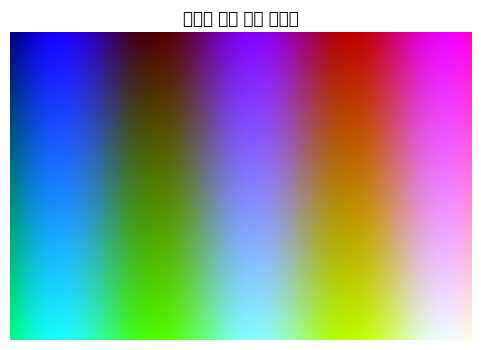

In [ ]:
import matplotlib.pyplot as plt
import platform

s = platform.system()
plt.rcParams['font.family'] = ('Malgun Gothic' if s == 'Windows'
                              else 'AppleGothic' if s == 'Darwin' else 'NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 그라데이션 이미지를 배열로 직접 만들기
h, w = 200, 300
yy, xx = np.mgrid[0:h, 0:w]

img = np.zeros((h, w, 3), dtype=np.uint8)
img[..., 0] = (xx / w * 255)                                  # R: 좌→우
img[..., 1] = (yy / h * 255)                                  # G: 상→하
img[..., 2] = (np.sin(xx / 20) * 127 + 128)                   # B: 물결

print('shape :', img.shape, ' dtype :', img.dtype, ' 크기 :', img.nbytes / 1024, 'KB')

plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.title('배열로 직접 만든 이미지')
plt.axis('off')
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 55121 (\N{HANGUL SYLLABLE HEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48177 (\N{HANGUL SYLLABLE BAEG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45236 (\N{HANGUL SYLLABLE NAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/u

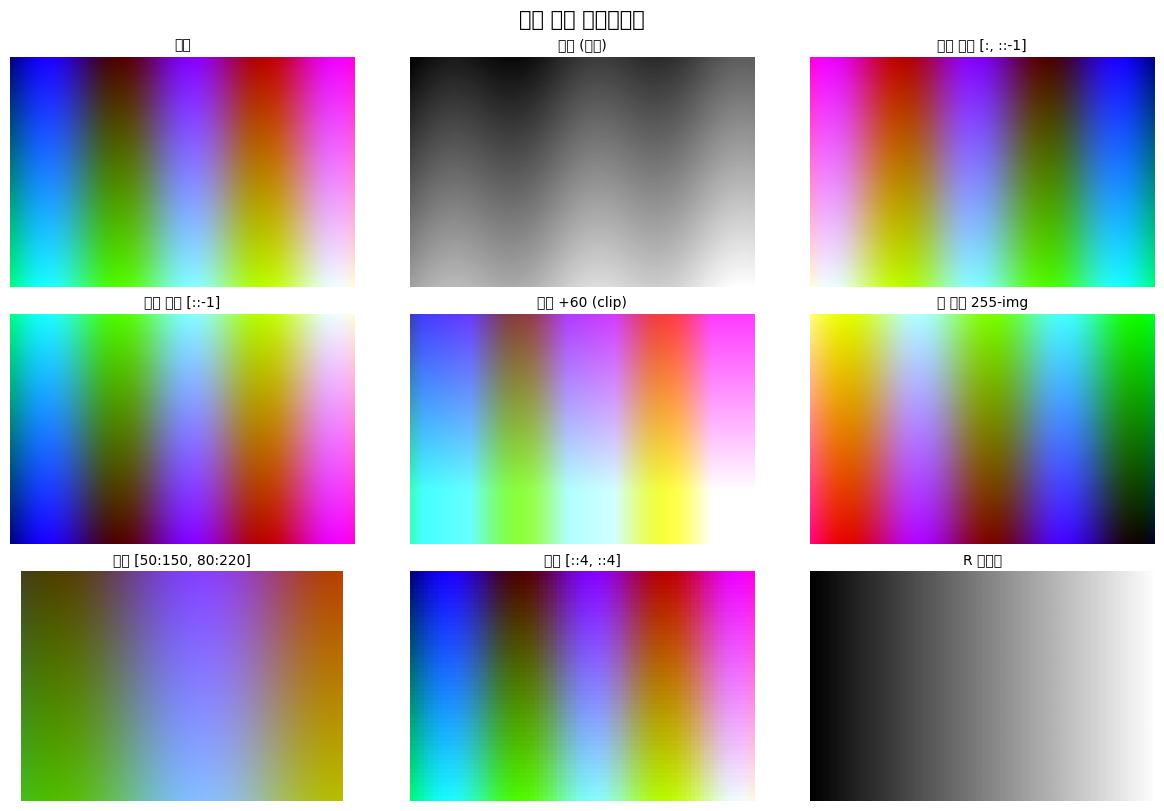

In [ ]:
# 배열 연산 = 이미지 처리
gray = (img @ np.array([0.299, 0.587, 0.114])).astype(np.uint8)   # 가중 평균으로 흑백

ops = [
    ('원본', img),
    ('흑백 (내적)', gray),
    ('좌우 반전 [:, ::-1]', img[:, ::-1]),
    ('상하 반전 [::-1]', img[::-1]),
    ('밝기 +60 (clip)', np.clip(img.astype(int) + 60, 0, 255).astype(np.uint8)),
    ('색 반전 255-img', 255 - img),
    ('크롭 [50:150, 80:220]', img[50:150, 80:220]),
    ('축소 [::4, ::4]', img[::4, ::4]),
    ('R 채널만', img[..., 0]),
]

fig, axes = plt.subplots(3, 3, figsize=(12, 8), constrained_layout=True)
for ax, (title, im) in zip(axes.flat, ops):
    ax.imshow(im, cmap='gray' if im.ndim == 2 else None)
    ax.set_title(title, fontsize=10)
    ax.axis('off')
fig.suptitle('전부 배열 연산입니다', fontsize=15)
plt.show()

## 10.2 몬테카를로 시뮬레이션 — 원주율 구하기

정사각형에 점을 무작위로 뿌리고, 원 안에 들어간 비율로 π 를 추정합니다.

  점      1,000개 → π ≈ 3.08400  (오차 0.05759)
  점    100,000개 → π ≈ 3.15012  (오차 0.00853)
  점  5,000,000개 → π ≈ 3.14225  (오차 0.00066)


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47788 (\N{HANGUL SYLLABLE MON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53580 (\N{HANGUL SYLLABLE TE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52852 (\N{HANGUL SYLLABLE KA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47484 (\N{HANGUL SYLLABLE REUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52628 (\N{HANGUL SYLLABLE CU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

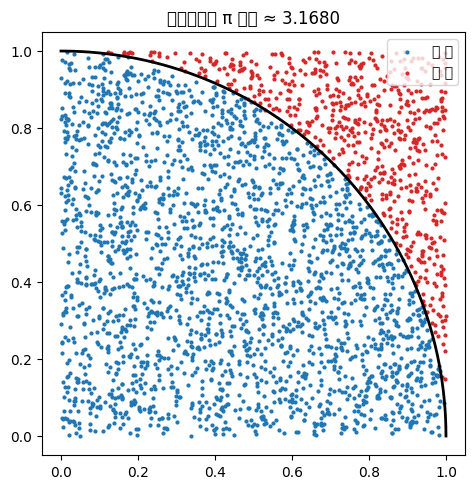

In [ ]:
rng = np.random.default_rng(42)

for n in [1_000, 100_000, 5_000_000]:
    pts = rng.random((n, 2))                       # [0,1) x [0,1)
    inside = (pts ** 2).sum(axis=1) <= 1.0         # 원점에서 거리 <= 1
    pi = 4 * inside.mean()
    print(f'  점 {n:>10,}개 → π ≈ {pi:.5f}  (오차 {abs(pi - np.pi):.5f})')

# 시각화
n = 3000
pts = rng.random((n, 2))
inside = (pts ** 2).sum(axis=1) <= 1.0

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(pts[inside, 0], pts[inside, 1], s=4, color='tab:blue', label='원 안')
ax.scatter(pts[~inside, 0], pts[~inside, 1], s=4, color='tab:red', label='원 밖')
th = np.linspace(0, np.pi / 2, 200)
ax.plot(np.cos(th), np.sin(th), 'k', lw=2)
ax.set(aspect='equal', title=f'몬테카를로 π 추정 ≈ {4*inside.mean():.4f}')
ax.legend()
plt.show()

## 10.3 주가 시뮬레이션 — 축을 이용한 대량 계산

반복문 하나 없이 **1만 개의 시나리오를 동시에** 굴립니다.

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/loc

1년 후 주가
  평균      :   108.25
  중앙값    :   105.20
  5% 분위   :    69.90
  95% 분위  :   158.22
  손실 확률 :    42.6%


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45208 (\N{HANGUL SYLLABLE NA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local

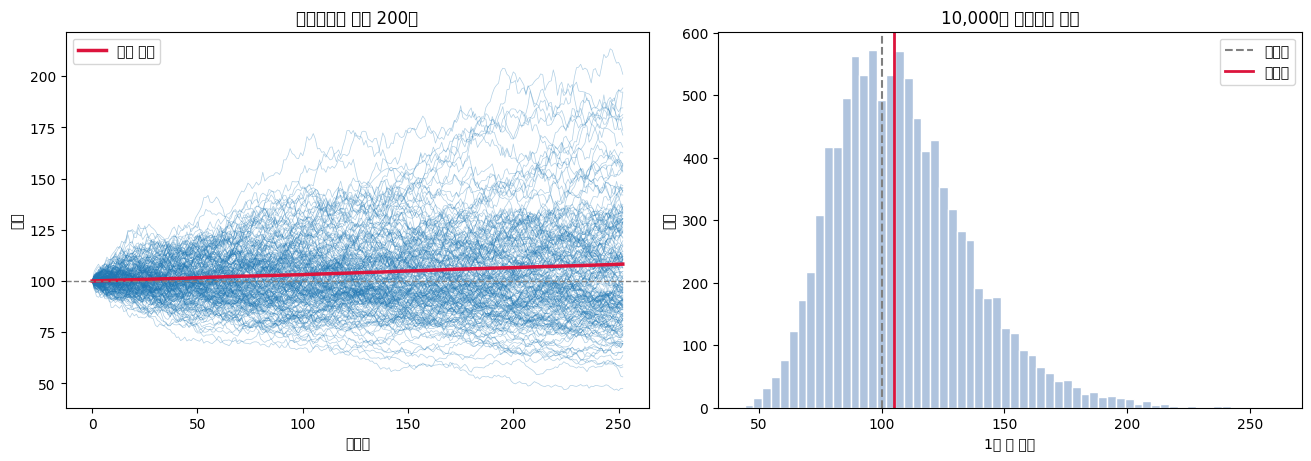

In [ ]:
rng = np.random.default_rng(7)

n_sim, n_days = 10_000, 252          # 시나리오 1만 개, 1년(거래일)
mu, sigma, s0 = 0.08, 0.25, 100.0
dt = 1 / n_days

# 각 날의 수익률을 한 번에 생성 (n_sim x n_days)
rets = rng.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), (n_sim, n_days))
paths = s0 * np.exp(np.cumsum(rets, axis=1))       # axis=1 = 시간 방향 누적
paths = np.hstack([np.full((n_sim, 1), s0), paths])

final = paths[:, -1]
print('1년 후 주가')
print(f'  평균      : {final.mean():8.2f}')
print(f'  중앙값    : {np.median(final):8.2f}')
print(f'  5% 분위   : {np.percentile(final, 5):8.2f}')
print(f'  95% 분위  : {np.percentile(final, 95):8.2f}')
print(f'  손실 확률 : {(final < s0).mean():8.1%}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].plot(paths[:200].T, lw=0.5, alpha=0.35, color='tab:blue')
axes[0].plot(paths.mean(axis=0), lw=2.5, color='crimson', label='평균 경로')
axes[0].axhline(s0, color='gray', ls='--', lw=1)
axes[0].set(xlabel='거래일', ylabel='주가', title='시뮬레이션 경로 200개')
axes[0].legend()

axes[1].hist(final, bins=60, color='lightsteelblue', edgecolor='white')
axes[1].axvline(s0, color='gray', ls='--', label='시작가')
axes[1].axvline(np.median(final), color='crimson', lw=2, label='중앙값')
axes[1].set(xlabel='1년 후 주가', ylabel='빈도', title=f'{n_sim:,}개 시나리오 분포')
axes[1].legend()
plt.show()

## 10.4 pandas · Matplotlib 과의 연결

In [ ]:
import pandas as pd

rng = np.random.default_rng(0)
arr = rng.normal(50, 12, (100, 3))

df = pd.DataFrame(arr, columns=['국어', '영어', '수학'])   # 배열 → DataFrame
back = df.to_numpy()                                        # DataFrame → 배열

print('DataFrame → 배열 :', type(back), back.shape)
print('같은 데이터?     :', np.allclose(arr, back))
print()
print('pandas 로 계산 :\n', df.mean().round(2))
print('\nNumPy 로 계산  :', arr.mean(axis=0).round(2))

# NumPy로 새 열 만들기
df['평균'] = arr.mean(axis=1)
df['등급'] = np.select([df['평균'] >= 60, df['평균'] >= 45], ['상', '중'], default='하')
print('\n', df.head())
print('\n등급 분포:\n', df['등급'].value_counts())

---

# 마무리

## 기억할 다섯 가지

1. **반복문이 보이면 벡터화를 의심하세요.** 대부분 한 줄로 바뀌고 수십 배 빨라집니다.
2. **슬라이스는 view입니다.** 원본을 지켜야 하면 `.copy()`.
3. **`axis=k` 는 k번째 축이 사라진다는 뜻**입니다. 결과 shape을 미리 예상해 보세요.
4. **브로드캐스팅은 오른쪽 끝부터 비교**합니다. 안 맞으면 `[:, None]` 로 축을 끼워 넣으세요.
5. **오류가 나면 `.shape` 부터 찍으세요.** 대부분 여기서 해결됩니다.

## 다음 단계

| 방향 | 도구 |
|---|---|
| 표 형태 데이터 · 결측치 · 그룹 집계 | **pandas** |
| 그래프 | Matplotlib, seaborn, Plotly |
| 과학 계산 (최적화·적분·신호처리) | SciPy |
| 머신러닝 | scikit-learn |
| 딥러닝 (NumPy와 문법이 거의 같음) | PyTorch, JAX |
| 초대용량 (메모리 초과) | Dask, Polars |

## 참고 자료

- 공식 문서: https://numpy.org/doc/stable/
- 입문 가이드: https://numpy.org/doc/stable/user/absolute_beginners.html
- 전체 함수 목록: https://numpy.org/doc/stable/reference/routines.html
- 브로드캐스팅 설명: https://numpy.org/doc/stable/user/basics.broadcasting.html

> NumPy는 함수가 수백 개라 외울 수 없습니다. **하고 싶은 일을 한국어로 적어 보고 그에 맞는 함수를 검색**하는 습관이 실무의 방식입니다.
